# **시계열**

## **1. 시계열 데이터란?**

### **1-1. 시계열 데이터의 정의**

#### **시계열 데이터란??**

: 시간의 흐름에 따라 일정한 간격, 순서대로 관측·기록된 데이터

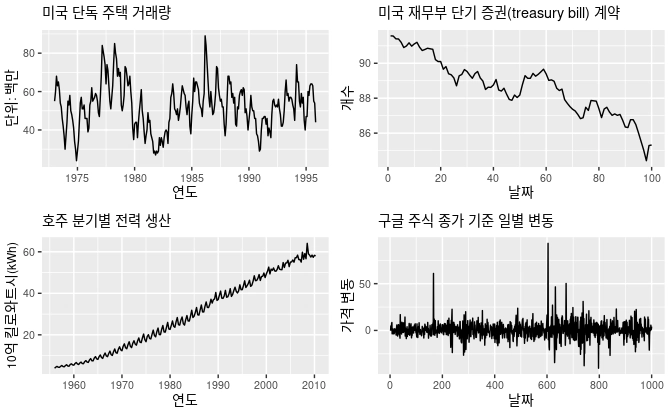

**표기**

$$
Y_1, Y_2, Y_3, \dots, Y_t, \dots, Y_T
$$

- $t$  : 시점 (time index) — 1일, 2일, 3일… 혹은 1월, 2월, 3월…
- $Y_t$ : $t$ 시점에 관측된 값
- $T$ : 마지막 관측 시점

#### **시계열 데이터의 조건**

- **시간 순서가 의미를 가짐** : 순서 자체가 정보여서, 순서가 섞이면 의미가 사라짐
- **관측 간격 일정** : 매초 / 매년 처럼 간격일 일정해야 시점끼리 비교 가능. 이 간격을 **주기**라고 함

**지금까지 데이터와의 차이점**

지금까지 다룬 데이터는 대부분 **횡단면 데이터!**

| 구분 | 횡단면 데이터 | 시계열 데이터 |
| --- | --- | --- |
| 관점 | **한 시점**에 **여러 대상**을 관찰 | **한 대상**을 **여러 시점**에 걸쳐 관찰 |
| 예시 | 2026년 서강대 학생 100명의 키 | 서강대 앞 식당 A의 2020~2026년 월별 매출 |
| 행 순서를 섞으면? | 아무 문제 없음 | **의미가 사라짐** |

#### **단변량 / 다변량 시계열**

**단변량 시계열**

- 시간에 따라 **하나의 변수만** 관측한 데이터
- 오로지 **자기 자신의 과거 값**만 보고 미래를 예측
- 적용 사례
    - 삼성전자의 일별 종가
    - 서울의 일별 평균 온도

**다변량 시계열**

- 시간에 따라 **여러 변수를 동시에** 관측한 데이터
- 자기 자신의 과거뿐 아니라 **다른 변수들의 영향**까지 함께 고려
- 적용 사례
    - 아메리카노의 판매량 <- 기온 + 강수량 + 요일
    - 주가 <- 거래량, 환율, 금리


#### **시계열 분석과 목적**

**시계열 분석이란?**

- 시간 순서대로 쌓인 데이터에서 **패턴을 찾아내고**, 이를 바탕으로 **미래 값을 예측**하는 분석 방법
- 시간에 따라 평균이나 변동폭이 어떻게 달라지는지 살펴보는 기초통계분석부터, 반복되는 패턴을 찾는 분석, 미래 값을 추정하는 예측까지 다양하게 활용

**시계열 분석의 주 목표 : 미래 데이터 예측 (Forecasting)**

: 지금까지의 기록을 보고 다음 시점, 그 다음 시점의 값을 추정하는 것

**시계열 예측의 기본 가정**

: **과거의 패턴이 미래에도 어느정도 반복될 것이다!**

**시계열 데이터의 활용방안**

시간에 따라 기록되는 숫자 = 시계열이기 때문에, 시계열 분석은 거의 모든 산업에서 활용됨

- **금융**: 주가·환율의 흐름을 보고 투자 판단. 카드 결제 패턴이 평소와 다르면 부정 사용을 실시간으로 차단.
- **유통/커머스**: 상품이 언제 얼마나 팔릴지 예측해서 재고를 준비.
- **에너지**: 전기는 저장이 어려워서 필요한 만큼만 생산해야 함. 그래서 시간대별 전력 수요를 예측해 발전량을 미리 조절.
- **기상**: 과거 기온·습도·기압의 흐름으로 일기예보를 만들고 재난에 대비.
- **IT 서비스**: 접속자 수·트래픽을 예측해 언제 서버를 늘려야 할지 정함.

⇒ 시계열 분석은 예측 자체가 목적이 아닌, **예측을 바탕으로 ‘미리’ 결정하기 위해** 사용!!

### **1-2. 시계열 데이터의 특징**

#### **1. 시간의존성 (Temporal Dependence)**

: **데이터가 시간에 따라 변하고, 현재 시점의 값이 과거 시점의 값에 영향을 받는 성질**

**특징**
1. 과거의 값이 현재의 값에 영향을 미침
2. 보통 가까운 과거일수록 영향이 큼
3. 순서를 섞으면 안됨

-> 시간에 따른 변화는 크게 두 가지 모양!
1. **계절성** : 일정하게 반복되는 모양
2. **추세** : 전반적으로 증가하거나 감소하는 모양

#### **2. 계절성 (Seasonality) & 추세 (Trend)**

**계절성 (언제마다 반복되나)**
- **일정한 주기(년, 월, 일 등)로 비슷한 패턴**이 반복되는 성질

**추세 (어느 방향으로 가나)**
- 시간의 흐름에 따라 데이터가 **장기적으로 증가/감소하는 방향성**
- 짧게는 오르락내리락해도, **멀리서 보명 한 방향**으로 움직이는 흐름 : 전반적 경향성 파악 가능
- 예시
    - 스마트폰 보급률 : 수년간 꾸준히 증가
    - 유선전화 가입자수 : 꾸준히 감소

#### **3. 자기상관성 (Autocorrelation)**

: 한 시계열 안에서, 현재 값과 과거 값이 얼마나 비슷하게 움직이는지를 나타내는 정도

**특징**

- 시간이 지남에 따라 값들 간 일정 패턴/반복 존재
- 값은 일반 상관계수와 같이 -1 ~ 1
    - 1에 가까움(비례) : 과거에 높았으면 지금도 높다
    - -1에 가까움(반비례) : 과거에 높았으면 지금은 낮다
    - 0에 가까움 : 과거와 지금은 관계가 없다
- 시차를 바꿔가며 계산할 경우 **반복주기(계절성)** 찾을 수 있음
    - 시차(Lag) : 현재 값을 몇 시점 전의 값과 비교하는지

**예시**

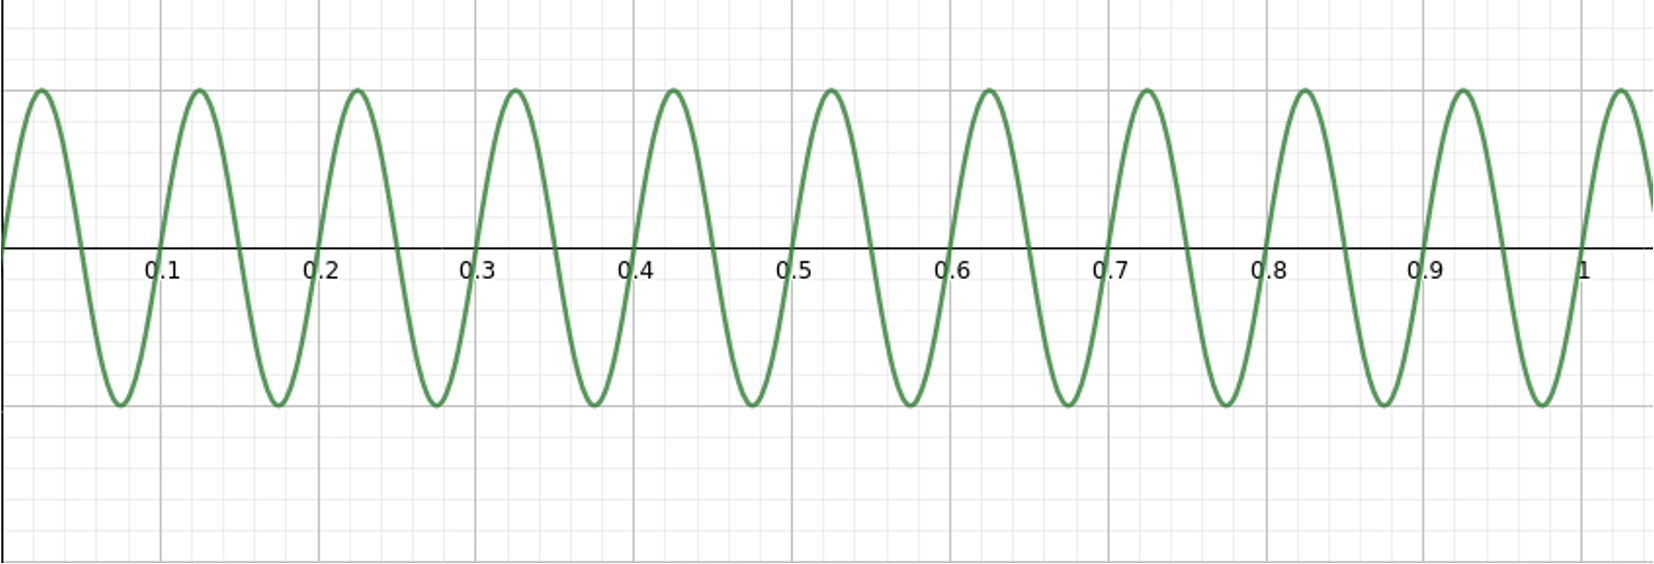

- 이 그래프는 0.1마다 같은 모양이 반복
- 0.1 전의 값과 비교하면 꼭대기는 꼭대기끼리, 바닥은 바닥끼리 만남 -> 자기상관이 1에 가까움
- 0.05전의 값(반주기)와 비교하면 꼭대기와 바닥이 만남 -> 자기상관이 -1에 가까움

**한 줄 정리: 자기상관이란 과거 값으로 지금 값을 짐작할 수 있는 정도!**

**문제점**

**: 회귀분석 불가!**

회귀분석은 데이터가 서로 독립적이라는 가정하에 **① 변수의 영향을 검정하고, ② 변수 간 관계를 찾고, ③ 미래를 예측.** 그런데 자기 상관이 있으면 이 세가지가 모두 흔들리기 때문에, 시계열 데이터에는 일반 회귀분석을 그대로 사용 불가.

1. **오차항 독립성 가정 위반 → 통계 결과 왜곡**
    - 회귀분석은 데이터에 선을 하나 그어 예측하는 방법이고, 이 회귀선이 예측한 값과 실제 값의 차이가 **오차**. 회귀분석은 이 오차끼리 서로 관계가 없다고 가정.
        
        : 즉, 어제와 오늘은 독립적!
        
    - 하지만 시계열은 오늘 값이 어제 값을 따라가기 때문에 **오차도** **어제를 따라감**.
        
        : 오차항이 독립적이지 않아 **통계적 추론의 왜곡 발생 (검정, 신뢰구간)**
        
2. **허위 상관관계 문제**
    - 둘 다 시간에 따라 증가/감소하는 시계열이면, 실제로 아무 관계가 없어도 상관관계가 높게 나옴.
        - ex) 넷플릭스 가입자 수와 서울 아파트 가격 → 회귀분석하면 관계가 강하게 나올 수 있지만, 넷플릭스가 집값을 올린게 아니라 둘 다 시간이 지나면서 각자 오른 것
    
    : 시계열끼리 상관관계가 높게 나오면 **혹시 둘 다 추세 때문 아닐까?**를 먼저 고려해보기!
    
- **3. 예측의 어려움 & 모델 복잡성 증가**
    - **시계열을 분석할 때는 과거와의 관계까지 모델에 넣어야 함**
        - 일반 회귀는 “기온이 오르면 판매량이 얼마나 오르나”만 보면 되지만, 시계열은 “어제 판매량이 오늘에 얼마나 영향을 주나”까지 설명해야 함.
    - **예측 오차가 쌓임**
        - 내일을 예측하고, 그 예측값으로 모레를 예측하다 보면, 첫날 조금 틀린게 눈덩이처럼 불어날 위험이 존재.
    - **패턴이 바뀔 수 있음**
        - 과거 패턴이 계속 유지된다는 보장 없음.

### **1-3. 시계열 데이터의 분석요인**

#### **1. 추세 요인 (Trend Factor)**

: **시계열이 시간 전반에 걸쳐 증가하거나 감소하는 경향성을 나타내는 요인**

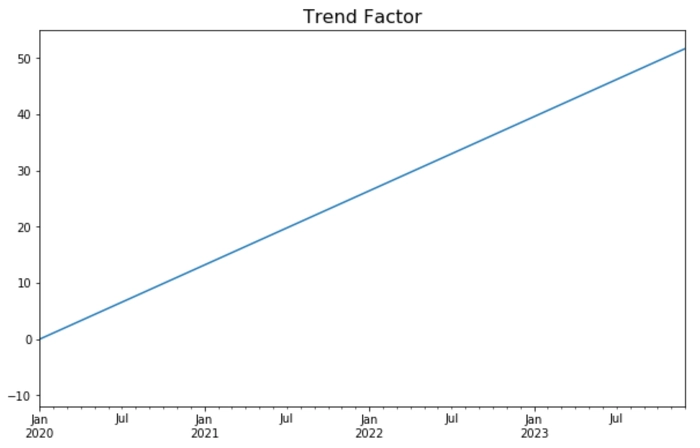

- 짧은 오르내림은 무시하고 큰 흐름만 본 것
- 인구 변화, 물가 상승 처럼 오랜 시간 걸쳐 작용하는 원인 때문에 생김

#### **2. 계절 요인 (Seasonal Factor)**

: **1년 이내의 일정한 주기로 같은 패턴이 반복되는 요인**

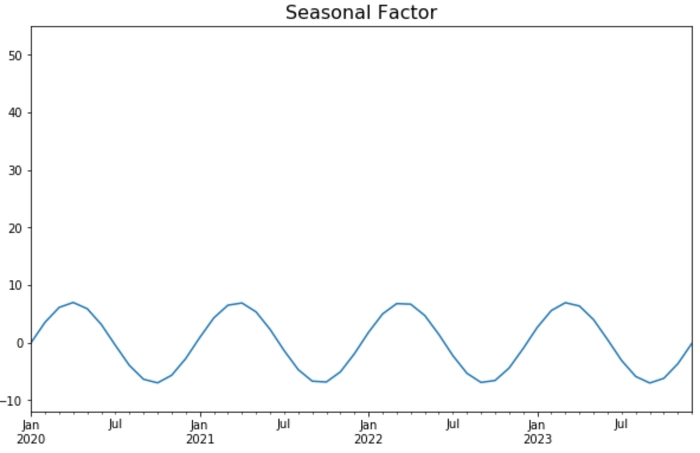

- 날씨, 달력(공휴일, 명절), 사회적 관습처럼 규칙적으로 돌아오는 원인 떄문에 생김

#### **3. 순환 요인 (Cycle Factor)**

: **계절성보다 더 길고 불규칙한 주기로 반복되는 변동**

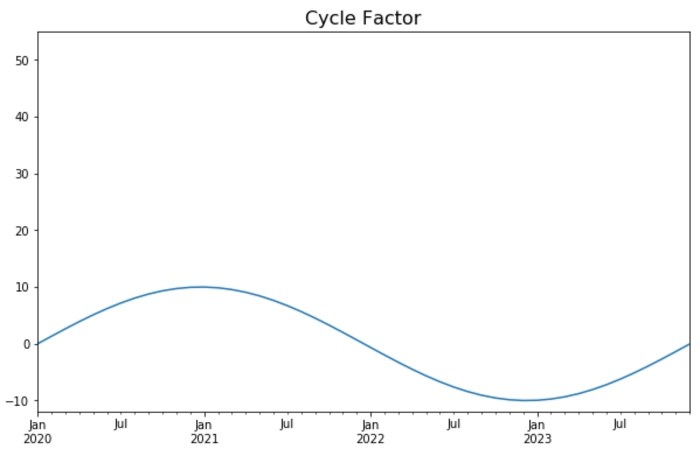

- 보통 1년 이상, 몇 년 단위의 움직임이라 긴 기간의 데이터 필요
- 대표적 원인 : **경기변동**
    - 경제는 호황 → 후퇴 → 불황 → 회복을 반복하지만 그 한 바퀴가 3년일 수도, 7년일 수도 있음

#### **4. 불규칙 요인 (Irregular Factor)**

: **시계열에서 추세, 계절, 순환요인을 모두 제거하고 남은 나머지 움직임**

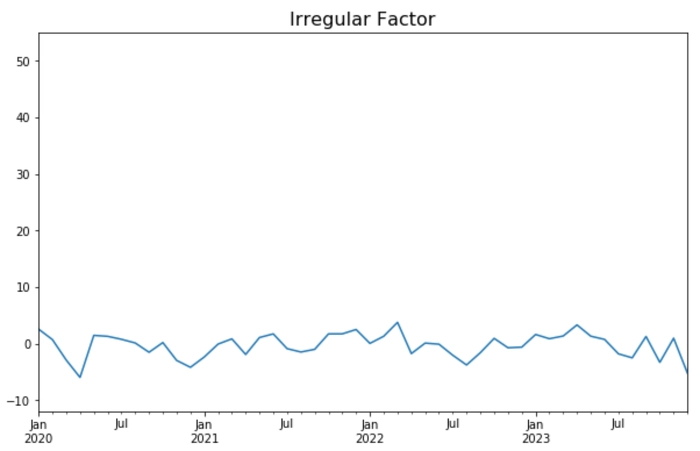

- 우연히 예측할 수 없이 생기는 변동으로 **잔차(Residual) 또는 노이즈(Noise)**라고 부름

#### **정리**

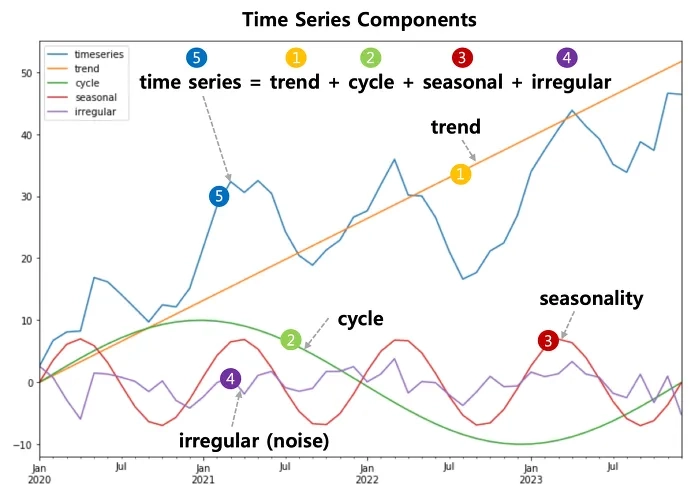

| 요인 | 의미 | 주기 | 예측 가능성 | 예시 |
| --- | --- | --- | --- | --- |
| 추세 (T) | 장기적인 방향 | 없음 | 높음 | 1인 가구 수 증가 |
| 계절 (S) | 정해진 주기의 반복 | 고정 (1년 이내) | 높음 | 여름 에어컨 판매 급증 |
| 순환 (C) | 불규칙한 주기의 오르내림 | 불규칙 (수년) | 낮음 | 경기 호황·불황 |
| 불규칙 (I) | 설명되지 않는 나머지 | 없음 | 불가능 | 폭우로 매출 급감 |

## **2. 시계열 데이터 전처리**

### **0. 전처리 필요성 및 프로세스**

#### **필요성**

: 시계열은 **값 하나가 앞뒤 갑소가 이어져 있기 떄문에,** 잘못된 값 하나가 주변 분석까지 망침

-> **시계열 데이터 특성이 왜곡되지 않도록 시계엵 특성을 반영한 전처리 필요!**

#### **프로세스**

```python
① 데이터 확인         → 시간 인덱스 정리, 관측 간격 확인, 시각화
↓
② 결측치 탐지 & 처리   → 빠진 값을 찾아 합리적으로 채우기          (2-1)
↓
③ 이상치 탐지 & 처리   → 튀는 값을 찾아 삭제하거나 대체하기        (2-1)
↓
④ 평활화              → 노이즈를 줄여 큰 흐름 파악하기            (2-2)
↓
⑤ 요소분해            → 추세·계절·불규칙 요인으로 나눠 보기        (2-3)
↓
⑥ 정상성 판단 & 확보   → 모델에 넣을 수 있는 상태로 만들기         (3장)
```

### **2-1. 결측치/이상치 탐지 및 처리**

#### **시계열 데이터의 결측치**

- 결측치 : 특정 시점의 값이 수집되지 않았거나 누락된 것
- 행을 지우면 관측 간격이 깨져 시점끼리 비교할 수 없게 됨
- 전체 평균으로 채우면 시간 흐름이 무시됨.

⇒ 시계열의 결측치는 추세와 계절성이 왜곡되지 않게 앞뒤 흐름을 고려해서 채워야 함

#### **결측치 처리 방법**

| 방법 | 설명 | 시계열에서의 한계 |
| --- | --- | --- |
| **삭제** | 결측치가 있는 시점을 제거 | 관측 간격이 깨짐 → 결측이 매우 적고, 데이터 맨 앞이나 맨 뒤일 때만 고려 |
| **단순 대치** | 평균, 중앙값, 최빈값으로 채움 | 추세와 계절성을 무시함 |
| **보간** | 앞뒤 관측값을 이용해 사이의 값을 추정 | 앞뒤 값이 있어야 함 → **시계열에서 가장 많이 사용** |
| **이동평균 대치** | 결측 시점 주변 일정 구간의 평균으로 채움 | 구간 크기를 정해야 함 (`2-2`에서 자세히) |
| **머신러닝 기법** | KNN, 회귀 모델 등으로 결측값을 예측해서 채움 | 정교하지만 복잡하고 계산량이 많음 |

**보간법 (시계열에서 가장 중요하고 많이 쓰이는 방법)**

- **주어진 데이터 포인트 값을 이용해, 두 관측값 사이의 비어있는 값을 추정**하는 방법
- 결측치 바로 앞뒤의 값을 연결해서 그 사이를 합리적으로 메워줌. 시계열은 시간의존성 덕분에 어제와 내일의 값을 알면 오늘 값을 꽤 정확히 짐작할 수 있기에, 보간법은 이 성질을 이용!
- **보간 방법 종류**
    - 선형 보간법 (linear Interpolation)
    - 다항식 보간법 (Polynomial Interpolation)
    - 스플라인 보간법 (Spline Interpolation)
    - 조각별 상수 보간법(Piecewise Constant Interpolation)

### **시계열 데이터 이상치**

- **이상치 : 데이터 일반적인 패턴에서 크게 벗어난 극단적인 값**
- 시계열의 이상치는 언제 나타났는지가 중요! 같은 값이라도 시점에 따라 정상일 수도, 이상일 수도 있음

→ 그래서 시계열에서는 값의 크기만 보지 않고, 추세와 계절성을 고려해서 이상치를 판단해야 한다!

#### **이상치 탐지 방법**

**1. IQR Rule-base Anomaly Detiction**

데이터를 크기순으로 나열했을 때 하위 25% 지점(Q1)과 상위 25% 지점(Q3) 사이의 범위를 IQR(Interquartile Range)이라고 함. 이 범위에서 너무 멀리 떨어진 값을 이상치로 판단

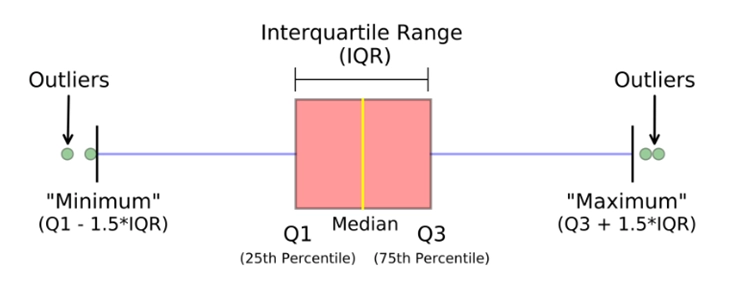

- **시계열에서 적용 방법**
    - 주기성이 없거나 비교적 안정적인 구간의 값들에서 이상치 탐지할 때 사용
    - 일정 구간을 이동하면서 구간마다 IQR을 계산하거나, 추세나 계절성을 제거한 잔차에 적용
- **장점**
    - 계산이 간단하고 직관적
    - 데이터가 정규분포를 따르지 않아도 사용 가능
- **단점**
    - 추세나 계절성이 강한 시계열에는 부적합
    - 분포가 비정상적일 경우 오탐률이 높음

**2. Z-score**

각 값이 평균에서 몇 표준편차만큼 떨어져 있는지를 계산하는 방법. 보통 Z-score의 절대값이 3보다 크면 이상치로 판단!

$$
        Z = \frac{x - \mu}{\sigma}
$$

→ x는 관측값, μ는 평균, σ는 표준편차. Z가 3이라는 건 평균보다 표준편차 3배만큼 크다는 뜻.

- **시계열에서 적용 방법**
    - 계절성/추세가 약하거나 값의 변동폭이 일정한 시계열에서 효과적
    - 이동 평균과 이동 표준편차로 구간마다 Z-score를 계산하면 추세의 영향을 줄일 수 있음 (Rolling Z-score)
- **장점**
    - 계산이 간단하고 해석이 쉬움
- **단점**
    - 데이터가 정규분포를 따른다고 가정
    - 평균과 표준편차가 이상치 자체에 영향을 받음 → 큰 이상치가 기준을 끌어올려 오히려 잘 안잡힐 수 있음

**3. STL 분해**

$$
        Y_t = T_t + S_t + R_t
$$

시계열을 **추세(T), 계절(S), 잔차(R)** 로 분해하는 방법.

- **시계열에서 적용 방법**
    - 잔차가 특정 임곗값을 초과하면 이상치 탐지
    - 계절성이나 추세가 뚜렷한 시계열(예: 일별 매출, 센서 데이터)에 적합
    - 잔차에 IQR이나 Z-score 등 통계적 기준을 추가 적용해 이상 탐지 가능
- **장점**
    - 추세와 계절성을 제거하고 “진짜 이상한 값”만 잡아낼 수 있음
    - 비정상 시계열에도 유연하게 적용 가능
- **단점**
    - 매우 긴 시계열에는 파라미터 튜닝이 필요함
    - 계산비용이 큼

#### **이상치 탐지 모델**

**1. 분류 및 회귀 트리 (CART)**

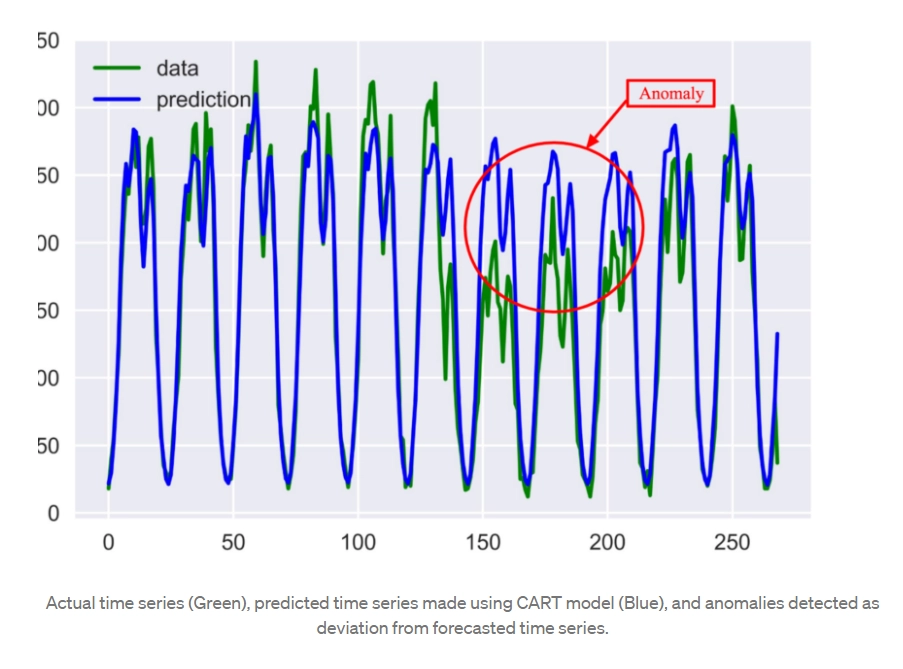

- **원리**
    - **CART(Classification And Regression Tree)** : 데이터를 조건에 따라 계속 나눠 가며 예측하는 의사결정나무 모델
    - 예측 오차가 일정 임계값 이상인 지점을 이상치로 판단
- **시계열 적용 방법**
    - 과거 구간의 값을 입력으로 하여 다음 시점의 값을 예측하고, 예측오차 기반으로 이상치를 판단
- **장점**
    - 비선형 관계를 잘 포착
    - 변수 간 상호작용이 있는 시계열(다변량)에도 적용 가능
- **단점**
    - 노이즈가 많은 데이터에서는 **과적합**되기 쉬움
    - 트리의 깊이에 따라 탐지 민감도가 달라짐
    
**2. 클러스터링 기반 이상 탐지**

- **원리**
    
    **군집화(Clustering)**진행 후, **어느 군집에도 잘 속하지 않는 데이터**를 이상치로 판단
    
    - **K-means** : 군집 중심에서 너무 멀리 떨어진 데이터를 이상치로 판단
    - **DBSCAN** : 밀집된 영역에 속하지 못하고 혼자 떨어진 데이터를 노이즈(이상치)로 분류
- **시계열 적용 방법**
    - 시계열의 특징을 추출한 후, 각 시점을 벡터로 표현해 클러스터링 수행 ( ex. 최근 5분 평균, 표준편차 기울기 등의 특징)
    - 중심으로부터의 거리나 군집 밀도를 기준으로 이상치 판단
- **장점**
    - 정답 라벨 없이 사용 가능 (비지도학습)
    - 값 하나가 아니라 **패턴 전체가 이상한 경우(집단 이상치)**도 잡을 수 있음
- **단점**
    - 군집 수(K)나 거리 기준 같은 **하이퍼파라미터 설정**에 따라 결과가 크게 달라짐
    - 시계열의 순서 정보는 직접적으로 반영되지 않음

**3. 오토 인코더**

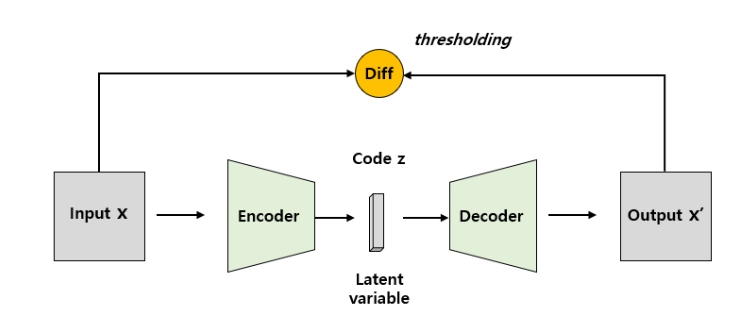

- **원리**
    
    입력 데이터를 **작게 압축(Encoder)**했다가 다시 **원래대로 복원(Decoder)**하도록 학습하는 신경망. **정상 데이터만으로 학습**시키면, 모델은 정상 패턴만 잘 복원하게 됩니다.
    
    그래서 이상치가 들어오면 제대로 복원하지 못하고, **원본과 복원값의 차이(복원 오차)**가 커짐. 이 오차가 기준보다 크면 이상치로 판단.
        
- **시계열 적용 방법**
    - LSTM Autoencoder를 사용하면 시계열의 시간적 의존성까지 학습 가능
    - 시계열을 일정 길이로 잘라 정상 구간을 학습시키고, 테스트 구간의 복원오차가 큰 곳을 이상으로 탐지
- **장점**
    - 복잡한 비선형 패턴과 **다변량 시계열**도 다룰 수 있음
- **단점**
    - 학습에 **많은 데이터와 계산량**이 필요
    - 모델 해석이 어렵고, 파라미터 튜닝이 까다로움

| 방법 | 방식 | 시계열 맥락 고려 | 복잡도 |
| --- | --- | --- | --- |
| IQR | 사분위수 범위 기준 | 구간별로 적용해야 함 | 낮음 |
| Z-score | 평균·표준편차 기준 | Rolling으로 적용해야 함 | 낮음 |
| STL 분해 | 잔차에 기준 적용 | **추세·계절성 반영** | 중간 |
| CART | 예측값과 실제값 비교 | 특성 설계에 따라 다름 | 중간 |
| 클러스터링 | 군집에서 벗어난 구간 | 패턴 단위로 반영 | 중간 |
| 오토인코더 | 복원 오차 기준 | 복잡한 패턴까지 반영 | 높음 |

→ 처음에는 IQR, Z-score처럼 간단한 방법으로 시작.  계절성이 뚜렷하면 STL, 데이터가 크고 복잡하면 모델 기반 방법을 고려

#### **이상치 처리 방법**

이상치를 찾았다면, 먼저 **오류인지 실제 사건인지** 확인한 뒤 처리 방법을 정합니다.

- **삭제**
    - 이상치를 제거하는 방법
    - 단, 시계열에서 그냥 지우면 관측 간격이 깨지므로 **값을 비워서(NaN) 결측치로 바꾼 뒤** 다시 채워주는 경우가 많음.
- **단순 대치**
    - 평균, 중앙값 등으로 바꾸는 방법
    - 간단하지만 추세와 계절성을 무시한다는 한계가 있음.
- **보간**
    - 이상치를 결측치로 바꾼 뒤, 앞뒤 값으로 **보간해서 채우는 방법**
    - 시간 흐름을 반영할 수 있어 시계열에서 많이 사용함.

### **2-2. 평활화**

#### **평활화의 개념**

시계열 데이터의 **자잘한 오르내림(노이즈)을 줄여 데이터를 부드럽게 만드는 기술**

실제 시계열 그래프는 매일매일 위아래로 들쭉날쭉해서, 데이터가 전체적으로 오르고 있는지 내리고 있는지 한눈에 보기 어려움. 평활화를 하면 이 들쭉날쭉함이 줄어들면서 **데이터의 큰 흐름**이 드러남.

평활화는 모델링 전에 **데이터가 어떤 모양인지 탐색하는 과정(EDA)**에서 주로 사용

#### **이동평균 (가장 대표적인 평활화 방법)**

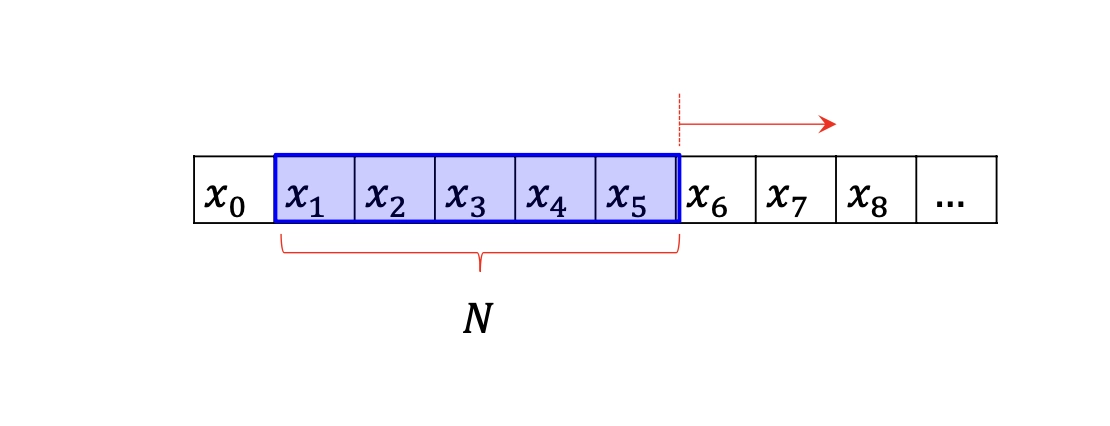

- **이동 평균**은 일정한 개수의 연속된 데이터를 묶어 평균을 내고, 그 묶음을 **한 칸씩 옮겨가며** 평균을 계속 계산하는 방법.
- 여기서 **N은 한 번에 평균을 낼 데이터의 개수**, 즉 **묶음의 크기(윈도우 크기)**를 의미.

$$
    MA_t = \frac{Y_t + Y_{t-1} + \cdots + Y_{t-N+1}}{N}
$$

→ t 시점의 이동평균은 t 시점부터 N개 전까지의 값을 모두 더해 N으로 나눈 값

**N 크기에 따른 차이**

| N | 결과 | 장점 | 단점 |
| --- | --- | --- | --- |
| **작을 때** | 원래 데이터와 비슷하게 움직임 | 최근 변화에 빠르게 반응 | 노이즈가 많이 남음 |
| **클 때** | 그래프가 매끄러워짐 | 큰 흐름이 잘 보임 | 변화에 늦게 반응하고, 세부 변화가 사라짐 |

**사용 목적**
1. **노이즈 제거 & 추세 파악**: 자잘한 변동을 줄여 데이터가 장기적으로 어디로 가는지 보여줌
2. **계절성 제거**: N을 계절 주기와 똑같이 맞추면, 한 주기 안의 오르내림이 평균에 모두 포함돼 상쇄됨
3. **결측치·이상치 대치**: 빠지거나 튀는 값을 주변 구간의 평균으로 채움
4. **예측의 기초 자료**: 시계열 예측(ARIMA)의 기반이 되기도 함

**유형**
- **단순 이동평균 (SMA, Simple Moving Average)**
    - 묶음 안의 모든 값에 **똑같은 가중치**를 주고 평균을 내는 방법
    - **장점**: 계산이 간단하고 직관적
    - **단점** : 3일 전 값과 오늘 값을 똑같이 취급해서 최근 변화에 늦게 반응함
- **가중 이동평균 (WMA, Weighted Moving Average)**
    - **최근 값일수록 더 큰 가중치**를 주는 방법
    - **장점**: 단순 이동평균보다 최근 변화에 빠르게 반응
    - **단점**: 가중치를 어떻게 줄지 직접 정해야 함
- **지수 이동평균 (EMA, Exponential Moving Average)**
    - 최근 값에 큰 가중치를 주되, **과거로 갈수록 가중치가 지수적으로 줄어드는** 방법. 묶음 크기 없이 **모든 과거 값을 조금씩** 반영
    - **장점** : 최근 변화에 빠르게 반응하면서도 과거 정보를 모두 반영, 계산이 효율적
    - **단점** : α 값을 정해야 하고, 직관적으로 이해하기 조금 어려움

### **2-3. 요소분해(Decomposition, 시계열 분해)**

#### **요소 분해**

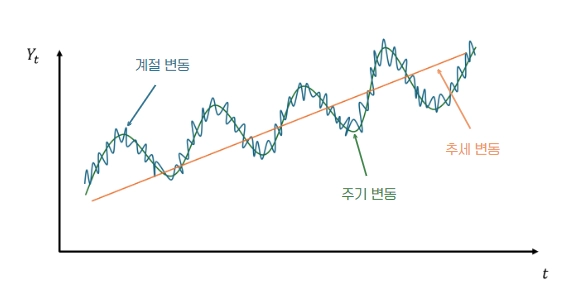

: 섞여 있는 시계열을 **각각의 요인으로 다시 나누는 과정**

$$
	Y_t = f(T_t, S_t, C_t, R_t)
$$

- **Tₜ** : 추세 요인 (Trend)
- **Sₜ** : 계절 요인 (Seasonal)
- **Cₜ** : 순환 요인 (Cycle)
- **Rₜ** : 불규칙 요인 (Residual, 잔차)

→ 실제 관측값 Yₜ는 이 네 요인이 어떤 방식(f)으로 결합된 결과! (순환 요인은 따로 찾아내기 어렵기 때문에, 실제로는 **추세에 포함시켜** 추세(T), 계절(S), 잔차(R) **세 가지로 분해**하는 경우가 대부분)

**요소분해를 하는 이유**
1. **각각의 패턴을 명확히 이해 가능**
2. **변동의 원인 분석 가능**
3. **더 정교한 분석 가능**

#### **분해 모형 (수학적 형태로의 분해)**

**1. 가법 모형 (Additive Model)**

$$
    Y_t = T_t + S_t + R_t
$$

- 시계열 = 추세, 계절, 잔차를 **더한 값**
- 시계열의 관측 값은 변동 요인들의 **가법(+)**으로 설명될 수 있다고 가정
- **각 변동 요인들이 독립적으로 더해지며, 모든 요소의 영향이 일정**
- 시계열 전체에서 계절성의 진폭이 일정할 때 적합

**2. 승법 모형 (Multiplicative Model)**

$$
    Y_t = T_t \times S_t \times R_t
$$

- 시계열 = 추세, 계절, 잔차를 **곱한 값**
- 시계열의 관측 값은 변동 요인들의 **승법(x)**으로 설명될 수 있다고 가정
- **추세가 커질수록 계절성이나 불규칙성의 효과도 비례해서 커짐**
- 진폭이 시간에 따라 달라질 때 적합
    - 승법 모형에 로그를 취하면?
        
        $$
                \log Y_t = \log T_t + \log S_t + \log R_t
        $$
        
        승법 모형 데이터에 로그를 취하면 **가법 모형처럼** 다룰 수 있음!

| 구분 | 가법 모형 | 승법 모형 |
| --- | --- | --- |
| 결합 방식 | 더하기 | 곱하기 |
| 계절 변동 크기 | 추세와 상관없이 **일정** | 추세에 **비례해서 커짐** |
| 계절 요인 단위 | 원래 데이터와 같은 단위 (잔, 원) | 비율 (배, %) |
| **그래프 모양** | **물결 높이가 일정** | **물결 높이가 점점 커짐** |

#### **분해 방법 (구현 알고리즘)**

**1. Seasonal Decompose - MA 기반 분해**

- **원리**
    - 가장 기본적이고 전통적인 분해 방법으로, **이동평균(MA)으로 추세를 먼저 뽑아낸 뒤** 나머지에서 계절과 잔차를 차례로 분리
- **작동방식**
    1. **추세 추출**
        - 중심 이동 평균을 적용하여 추세 성분(T)을 추정
    2. **Detrending (추세 제거)**
        - 원래 데이터에서 추세(T)를 제거
        - 가법 모형 : Y − T / 승법 모형 : Y ÷ T
        - 이제 데이터에는 **계절 + 잔차**만 남아 있음
    3. **계절성 추정**
        - 추세를 제거한 데이터에서 동일한 계절 인덱스에 해당하는 값들의 평균을 취해 계절 요인(S)을 도출. 이때 연간 평균이 0이 되도록 정규화
    4. **잔차 산출**
        - 원래 데이터에서 추세와 계절을 모두 제거하고 남은 값 = **잔차(R)**
        - 가법 모형 : Y − T − S / 승법 모형 : Y ÷ (T × S)

**2. STL - LOESS 기반 분해**

STL은 Seasonal Decompose의 한계를 보완한 방법. 이동평균 대신 LOESS를 사용해 추세와 계절을 추정

- **원리**
    - 데이터 전체에 선 하나를 긋는 대신, **각 지점마다 주변 데이터만 사용해서** 작은 회귀선을 그리고 이를 이어 붙여 부드러운 곡선을 만드는 방법이에요. 가까운 데이터일수록 더 큰 가중치를 줍니다.
        
        → 전체를 하나의 규칙으로 맞추지 않고 **구간마다 유연하게** 맞추기 때문에, 시간에 따라 바뀌는 추세와 계절 패턴도 잘 잡아내요.
        
- **작동방식**
    
    STL은 Inner Loop와 Outer Loop의 이중 반복 구조로 구성
    
    - **Inner Loop: 추세와 계절을 번갈아 추정**
        1. 원래 데이터에서 현재 추세를 빼서 **추세를 제거**
        2. 추세를 제거한 데이터를 **같은 계절 위치끼리** 모아 LOESS로 부드럽게 만듦 → **계절 요인(S)** 추정
        3. 원래 데이터에서 계절 요인을 빼서 **계절성을 제거**
        4. 계절성을 제거한 데이터에 LOESS를 적용 → **추세 요인(T)** 추정
        5. 새로 구한 추세로 다시 1번부터 반복하며 T와 S를 점점 정확하게 다듬음
    - **Outer Loop: 이상치 영향 줄이기**
        1. Inner Loop가 끝나면 **잔차(R = Y − T − S)**를 계산
        2. 잔차가 유독 큰 시점(이상치일 가능성이 높은 시점)에 **작은 가중치**를 부여
        3. 이 가중치를 반영해서 **Inner Loop를 다시 수행**
        
        → 이상치가 추세와 계절 추정을 왜곡하지 못하게 막아줌(**강건(robust)한 분해**)

#### **요소분해 정리**

: **시계열을 추세(T) + 계절(S) + 잔차(R)로 나누는 과정!**

- 시계열 데이터에 포함된 다양한 변동 요인을 분리해 원본 데이터를 명확히 파악할 수 있다!
- 복잡한 시계열 그래프를 요소별로 나눠 각 요소를 독립적으로 분석할 수 있다!
- 예측 모델링 전에 요소를 분리해두면 각 구성 요소를 개별적으로 모델링하거나 통제할 수도 있어 정확도 향상이 가능하다! (시계열 예측 모델에 적용)
- 잔차로 이상치를 찾고, 계절조정 데이터를 만드는 등 분석을 정교하게 할 수 있다!

**정상/비정상 시계열**

| 구분 | 정상 시계열 | 비정상 시계열 |
| --- | --- | --- |
| 평균 | 시간에 상관없이 **일정** | 시간에 따라 **변함** (추세) |
| 분산 | 시간에 상관없이 **일정** | 시간에 따라 **커지거나 작아짐** |
| 패턴 | 일정한 평균 주위를 오르내리며, 벗어나도 **다시 돌아옴** | 한 방향으로 흘러가거나, 주기적으로 반복됨 (계절성) |
| 예시 | 매일 주가의 **등락률(%)**, 공장 기계의 정상 가동 중 진동값 | 주가 **가격** 자체, 연도별 GDP, 월별 항공기 승객 수 |

**정상성 = 평균, 분산, 자기상관이 시간에 따라 변하지 않는 성질**

### **3-2. 강한 정상성과 약한 정상성**

#### **강한 정상성**

: **시계열의 확률분포 자체가 시간에 따라 전혀 변하지 않는 성질. 어떤 시점들을 골라 통째로 h만큼 옮겨도 분포는 완전히 똑같아야 함.**

$$
    (Y_{t_1}, Y_{t_2}, \dots, Y_{t_k}) \overset{d}{=} (Y_{t_1+h}, Y_{t_2+h}, \dots, Y_{t_k+h})
$$

→ **모든 k와 모든 h에 대해** 성립해야 함!

**특징**
- 평균, 분산뿐 아니라 **왜도, 첨도 등 분포의 모든 특성**이 시간에 따라 변하지 않고 일정

**한계**
- 현실 데이터는 잡음과 외부요인이 항상 존재하기 때문에 이런 상태는 거의 찾아볼 수 없음

#### **약한 정상성**

: 분포 전체가 아닌 **평균, 분산, 자기공분산**만 시간에 따라 변하지 않으면 되는 성질.
1. **평균이 일정하다** : 모든 시점의 평균이 같은 값 μ
2. **분산이 일정하다** : 모든 시점의 분산이 같은 값 σ² (무한대가 아님)
3. **자기공분산이 시차에만 의존한다** : 두 시점 사이의 공분산은 **특정 시점(t)이 아니라 시간의 간격(h)**에만 달려 있음

**특징**
- 강한 정상성보다 조건이 느슨해서 **현실 데이터에도 적용 가능**합니다.
- AR, MA, ARIMA 등 대부분의 시계열 모델이 가정하는 정상성이 바로 약한 정상성이에요.

### **3-3. 정상성 판단하기**

#### **1. 시각적으로 정상성 파악**

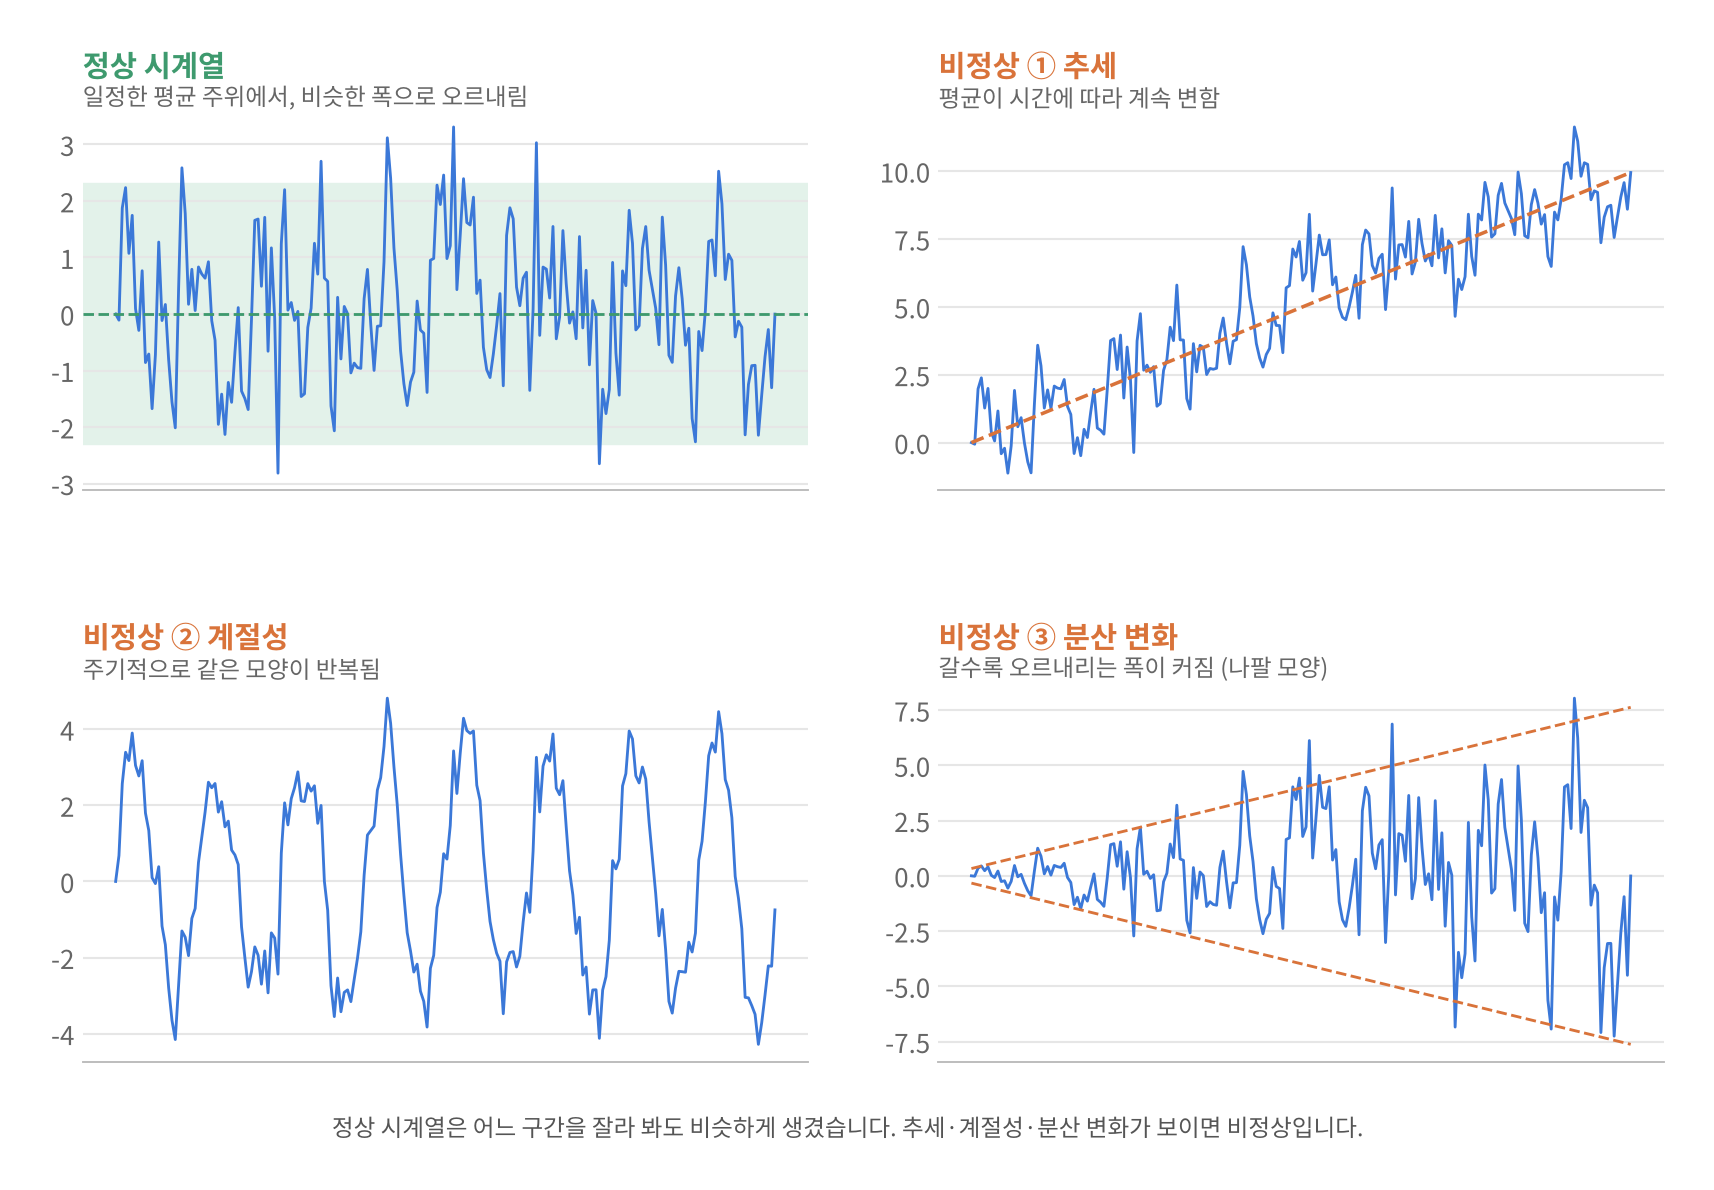

**정상 시계열의 대표적 특징**
- 일정한 **수평선(평균)**을 중심으로 위아래로 오르내림
- 오르내리는 **폭이 시간에 상관없이 비슷함**
- 평균에서 벗어나도 **다시 평균으로 돌아오는 경향** (평균 회귀)
- 특정 주기로 반복되는 패턴이 없음

**비정상 시계열의 대표적 특징**
- **추세** : 그래프가 계속 오르거나 내림 → 평균이 변함
- **계절성** : 일정한 주기로 같은 모양이 반복됨 → 시점에 따라 평균이 달라짐
- **분산 변화** : 시간이 지날수록 오르내리는 폭이 커지거나 작아짐 (나팔 모양) → 분산이 변함

#### **2. 통계적 검정(객관적 확인 방법)**

**단위근** : 시계열을 표현하는 식의 **근(해)이 1이 되는 경우**
- 과거 충격이 영구적으로 누적되는 특성
- 단위근은 계속 쌓여, 데이터가 **평균으로 돌아오지 않고 무작위로 떠돌게 됨**

-> **단위근이 있으면 비정상 시계열!**

**단위근의 시계열적 의미**
$$
        Y_t = \phi Y_{t-1} + \varepsilon_t
$$

- 오늘 값(Yₜ) = **어제 값(Yₜ₋₁)의 φ배** + **오늘 새로 생긴 충격(εₜ)**
- φ(파이)는 **어제 값이 오늘에 얼마나 남는가**

**충격이 쌓이면 생기는 문제**
1. 평균으로 돌아오지 않는다
2. 분산이 계속 커진다.

**단위근 검정 방법**
- **➀ ADF (Augmented Dickey-Fuller) 검정**
    
    시계열에 ”**단위근이 있는지”**를 검정하는 가장 대표적인 방법으로, “이 시계열이 비정상이 아님을 증명하자”는 관점에서 출발
    
    - **ADF는 시계열이 과거 값에 얼마나 의존하는지를 측정**
        
        과거 값의 영향이 시간이 지남에 따라 점점 사라지면 정상 시계열, 누적되어 사라지지 않으면 단위근이 존재하는 비정상 시계열로 판단
        
    - 가정
        - **귀무가설(H₀)** : 단위근이 **있다** → **비정상** 시계열
        - **대립가설(H₁)** : 단위근이 **없다** → **정상** 시계열
    
     ⇒ **p-value < 0.05**이면 귀무가설을 기각 → **정상**
    
- **➁ KPSS (Kwiatkowski-Phillips-Schmidt-Shin) 검정**
    
    ADF와 반대로, **“이 시계열이** **정상임을 반증하자”**는 관점에서 출발하는 검정
    
    - **KPSS는 시계열이 일정한 평균 수준을 유지하는지를 측정**
        
        평균이 시간에 따라 흔들리지 않으면 정상, 평균 자체가 계속 변하고 있으면 비정상으로 판단
        
    - 가정
        - **귀무가설(H₀)** : 시계열이 **정상**이다
        - **대립가설(H₁)** : 시계열이 **비정상**이다 (단위근이 있다)
    
    ⇒ **p-value < 0.05**이면 귀무가설을 기각 → **비정상**

**검정 결과 조합 해석**

| ADF 결과 | KPSS 결과 | 진단 | 다음 액션 |
| --- | --- | --- | --- |
| 정상 | 정상 | **정상 시계열** | 바로 모델링 진행 (4장) |
| 비정상 | 비정상 | **비정상 시계열** | **차분** 등으로 정상성 확보 후 재검정 (3-4) |
| 비정상 | **정상** | **추세 정상 시계열** | **추세 제거** 후 재검정 |
| **정상** | 비정상 | **차분 정상 시계열** | **차분** 후 재검정 |

- 두 모델 모두 **정상** : 정상 시계열
- 두 모델 모두 **비정상** : 비정상 시계열
- KPSS만 **정상** : **추세 정상 시계열**일 가능성 높음

### **3-4. 정상성 확보 방법**

#### **1. 추세 제거**

: **시계열이 장기적으로 한 방향으로 계속 오르거나 내려서, 시간간에 따라 평균이 변하는 경우에 적용**

**차분**

$$
\Delta Y_t = Y_t - Y_{t-1}
$$

차분이란 오늘 값에서 어제를 빼서, 값 자체 대신 **”얼마나 변했나”**를 보는 방법!

**차분을 통한 정상성 확보의 이유**

1. **추세가 사라짐**
2. **단위근이 사라짐**

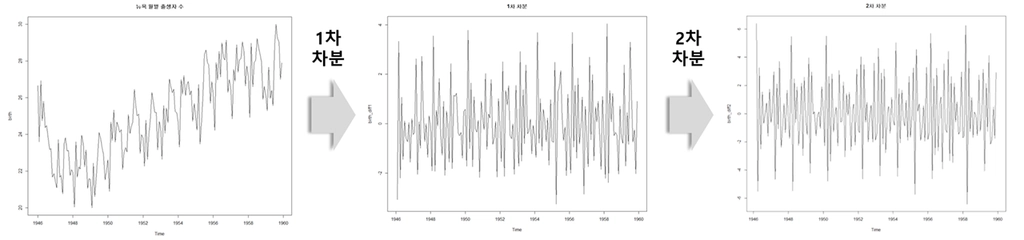

**종류**

- **1차 차분** : 위에서 본 기본 차분으로, 오늘 값에서 어제 값을 뺌
    
- **2차 차분** :1차 차분한 결과를 한번 더 차분 
    
    - 1차 차분을 해도 추세가 남아있을 때, 즉 오르는 속도 자체가 점점 빨라지는 곡선 형태의 추세를 없앨 때 사용

    - 단, 차분을 많이 하면 오히려 없던 패턴이 생기고 변동이 커질 수 있음. 그래서 보통 2차 차분까지만 하고, 차분할 때마다 검정으로 확인해서 정상이 되는 최소 횟수반 차분함.
- **역차분** : 차분한 값을 다시 원래 값으로 되돌림
    
    - 차분한 데이터로 예측하면 결과도 “변화량”으로 나오기 때문에, 원래 단위로 해석하려면 꼭 되돌려야 함.

#### **2. 계절성 제거**

: 시계열이 **시점에 따라 평균이 달라지는 경우에 적용**

**계절 차분**

$$
\Delta_m Y_t = Y_t - Y_{t-m}
$$

- 오늘 값에서 **한 주기(m) 전의 값**을 빼는 방법

#### **3. 분산 안정화**

: 시계열의 오르내리는 **폭이 시간이 지날수록 커지거나 작아져서,** 분산이 일정하지 않은 경우에 적용

**로그변환**

- 데이터에 로그를 취해서 값의 크기를 줄이는 방법
    - 로그는 값이 커질수록 함꼐 커지던 변동 폭이 비슷한 크기로 정리됨

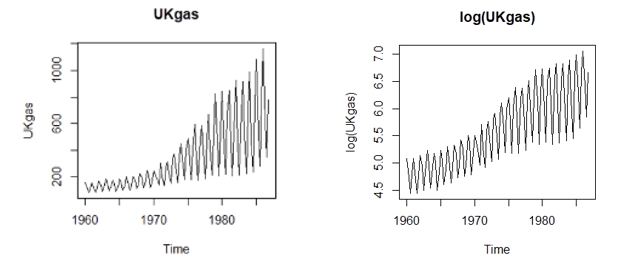

**한계점**
- 0이나 음수에는 쓸 수 없음. 로그는 양수에서만 계산되기 때문. 0이 포함된 데이터는 모든 값에 1을 더한 뒤 로그를 취하기도 함.
- 모든 분산 변화를 해결하진 못함. 값이 커질수록 변동 폭도 비례해서 커지는 경우에 효과적이고, 그 외의 형태에는 잘 맞지 않을 수 있음.

### **총정리**

시계열 분석은 결국 **‘정상성 확보 → 패턴 파악 → 적절한 모델링’**의 순환적 과정!

**정상 / 비정상 여부 판단**

시계열 분석의 출발점은 **정상 시계열인지 아닌지**를 판단하는 것

- **단위근 검정** 사용 (ADF, KPSS 등)
- 비정상이면 → 다음 단계로 이동

**비정상 유형에 따라 정상성 확보**

비정상 시계열이라고 해서 **무조건 차분**하는 건 아님

- **추세**가 있다면 → 차분, 추세 제거
- **계절성**이 있다면 → 계절 차분 or Deseasoning
- **분산 변화**가 있다면 → 로그변환, Box-Cox 변환

→ 적절한 방법을 선택해 정상성 확보

**정상성 확보 후 어떤 프로세스를 따르는지에 따라 모델링**

## **4. 단변량 시계열 분석**

### **4-1. 안정적 시계열(정상 시계열) 분석**

#### **1. 자기 회귀 모델 (Autoregressive Model, AR)**

: **오늘 값을 자기 자신의 과거 값으로 설명하는 모형** (자기상관성 활용)

예시 : 손님 = 어제 손님 수를 보고 찾아오는 가게

- **$AR(p)$ 모형**: 과거 p개 시점의 값 사용
    
    $$
    	y_{t}=c +\phi_1y_{t-1}+\phi_2y_{t-2}+...+\phi_py_{t-p}+\varepsilon _t
    $$
    
    - 시차마다 계수가 따로 있고, 값은 데이터에서 추정.
    - AR(2)라면 어제 손님의 수 뿐만 아니라 이틀 전 손님의 수도 오늘 판매량에 직접 영향을 줌.

- **$AR(1)$ 모형**: 바로 전 시점의 값 하나만 사용 (즉, p가 1일때)
    
    $$
    y_{t}=c +\phi_1y_{t-1}+\varepsilon _t
    $$
    
    - $y_t$ : 오늘 판매량. 지금 구하려는 값
    - $y_{t-1}$ : 어제 판매량
    - $\phi_1$ : 계수. 어제 판매량의 몇 %가 오늘 판매량에 반영되는지 나타냄. 0.8이면 80%임.
    - $\varepsilon_t$ : 오늘 새로 생긴 충격
    - c : 상수. 평소 수준은 $c \div (1-\phi_1)$이고, 값을 "평소 대비"로 쓰면 0이 됨.
    
    ⇒ 말하자면 **"오늘 판매량 = 어제 판매량의 일부 + 오늘 충격"**    

#### **이동 평균 모델 (Moving Average, MA)**

: **오늘 값을 과거의 충격으로 설명하는 모형**

- $MA(q)$ **모형**: 과거 q개 시점의 충격 사용
    
    $$
    y_t = \mu +\varepsilon_t+ \theta_1\varepsilon_{t-1}+\theta_2\varepsilon_{t-2}+...+\theta_q\varepsilon_{t-q}
    $$
    
    - MA(2)에서 계수가 0.6과 0.3이면, 충격 100의 여파는 다음 날 60, 이틀 뒤 30, 사흘 뒤 0이다. 계수가 여파의 크기로 그대로 나타나고, q일 뒤까지 남았다가 그다음 날부터 0이 된다.

- $MA(1)$ **모형**: 바로 전 시점의 충격 하나만 사용 (즉, q가 1일때)
    
    $$
    y_{t}=\mu +\varepsilon _t+ \theta_1\varepsilon_{t-1}
    $$
    
    - $\mu$ : 평균. 값을 "평소 대비"로 쓰면 0이 됩니다
    - $\varepsilon_t$ : 오늘 충격
    - $\varepsilon_{t-1}$ : 어제 충격
    - $\theta_1$ : 계수. 어제 충격의 몇 %가 오늘 판매량에 반영되는지 나타낸다. 0.8이면 80%이다.
    
    ⇒ **"오늘 판매량 = 오늘 충격 + 어제 충격의 일부"**

**AR/MA 비교**

|  | AR | MA |
| --- | --- | --- |
| 한 줄 요약 | 손님이 어제 손님 수를 보고 온다 | 손님이 어제 방송을 보고 온다 |
| 오늘 충격 | 오늘 값에 그대로 들어감 | 오늘 값에 그대로 들어감 |
| 지나간 충격 | 어제 값이라는 그릇에 담겨 넘어옴 | 충격 자체가 직접 넘어옴 |
| 영향이 가는 기간 | 끝없이 이어지며 옅어짐 | 정해진 날수 뒤에 끊김 |

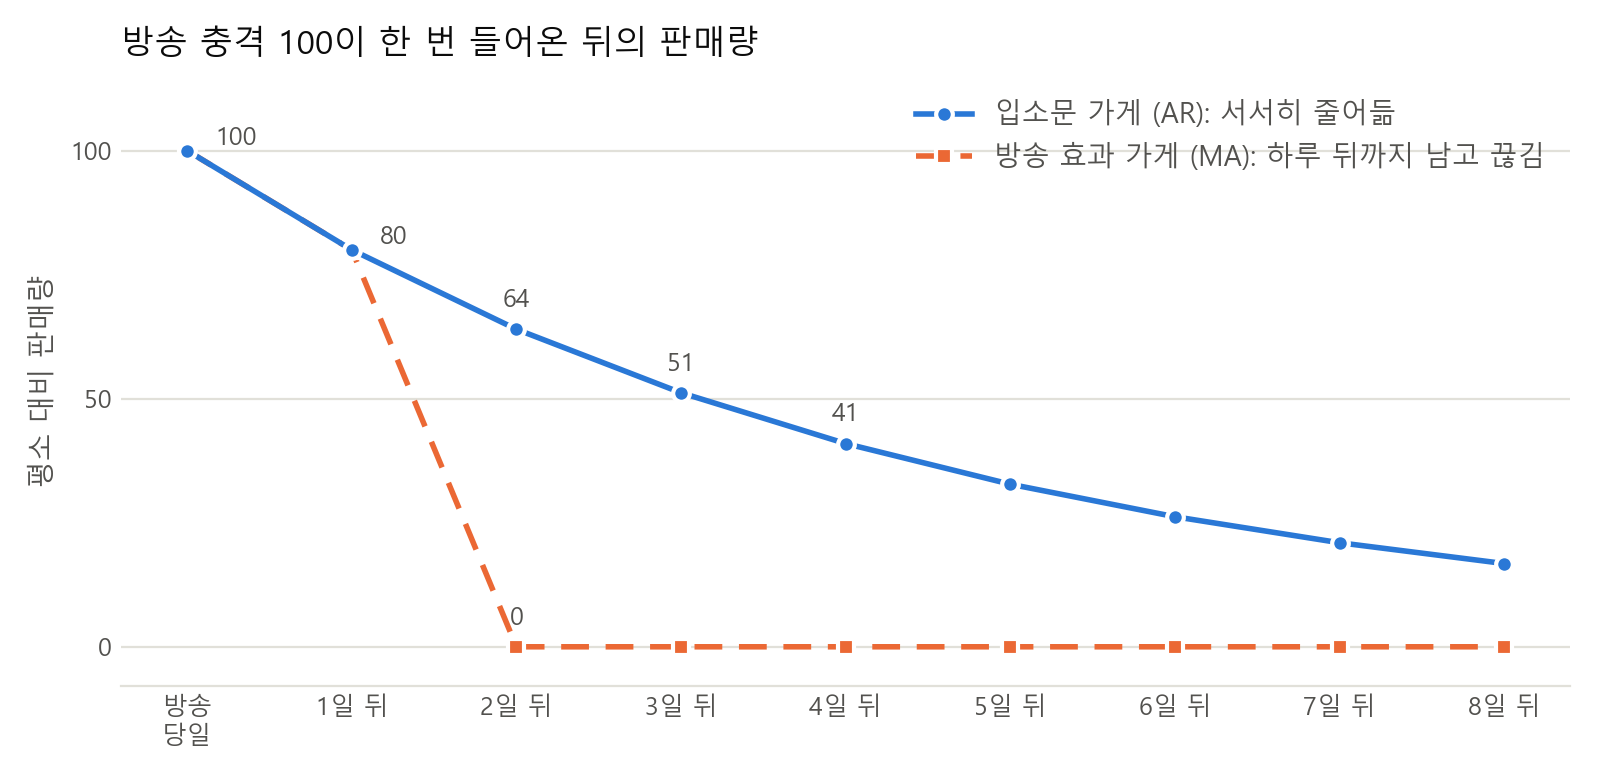

#### **AR/MA 모델의 전제 조건**

-> AR과 MA를 사용하려면 **정상성**과 **가역성** 필요

|  | 정상성 | 가역성 |
| --- | --- | --- |
| 뜻 | 충격을 받아도 평소로 돌아온다 | 판매량 기록으로 지난 충격을 계산해 낼 수 있다 |
| AR 모형 | 계수 조건이 필요 | 항상 만족 |
| MA 모형 | 항상 만족 | 계수 조건이 필요 |
| 계수 조건 | AR(1)이면 계수의 절댓값이 1보다 작다 | MA(1)이면 계수의 절댓값이 1보다 작다 |

**1. 정상성**

: 충격을 받아도 시간이 지나면 평소로 돌아온다!

**AR 모델의 조건**
- AR(1)은 계수의 절댓값이 1보다 작아야 함.
- AR(p)는 아래 특성방정식의 모든 근의 절댓값이 1보다 커야 함.

    $$
    1-\phi_1 z-\phi_2 z^2-\dots-\phi_p z^p=0
    $$

**MA 모델의 조건**
- **항상 정상**

**2. 가역성**

: 판매량 기록에서 지난 충격을 거꾸로 계산해 낼 수 있는 성질

**AR 모델 만족 조건**
- 항상 가역. **"오늘 충격 = 오늘 값 − 계수 × 어제 값"**이라서 필요한 숫자가 전부 관측 가능한 값.

**MA 모델 만족 조건**
- MA(1)은 계수의 절댓값이 1보다 작아야 함.        
- MA(q)는 아래 특성방정식의 모든 근의 절댓값이 1보다 커야 함.

    $$
    1+\theta_1 z+\theta_2 z^2+\dots+\theta_q z^q=0
    $$

#### **3. ARMA (Autoregressive Moving Average) 모형**

: **AR + MA** 인 모형. 오늘값이 과거 값과 과거 충격 양쪽의 영향을 받음

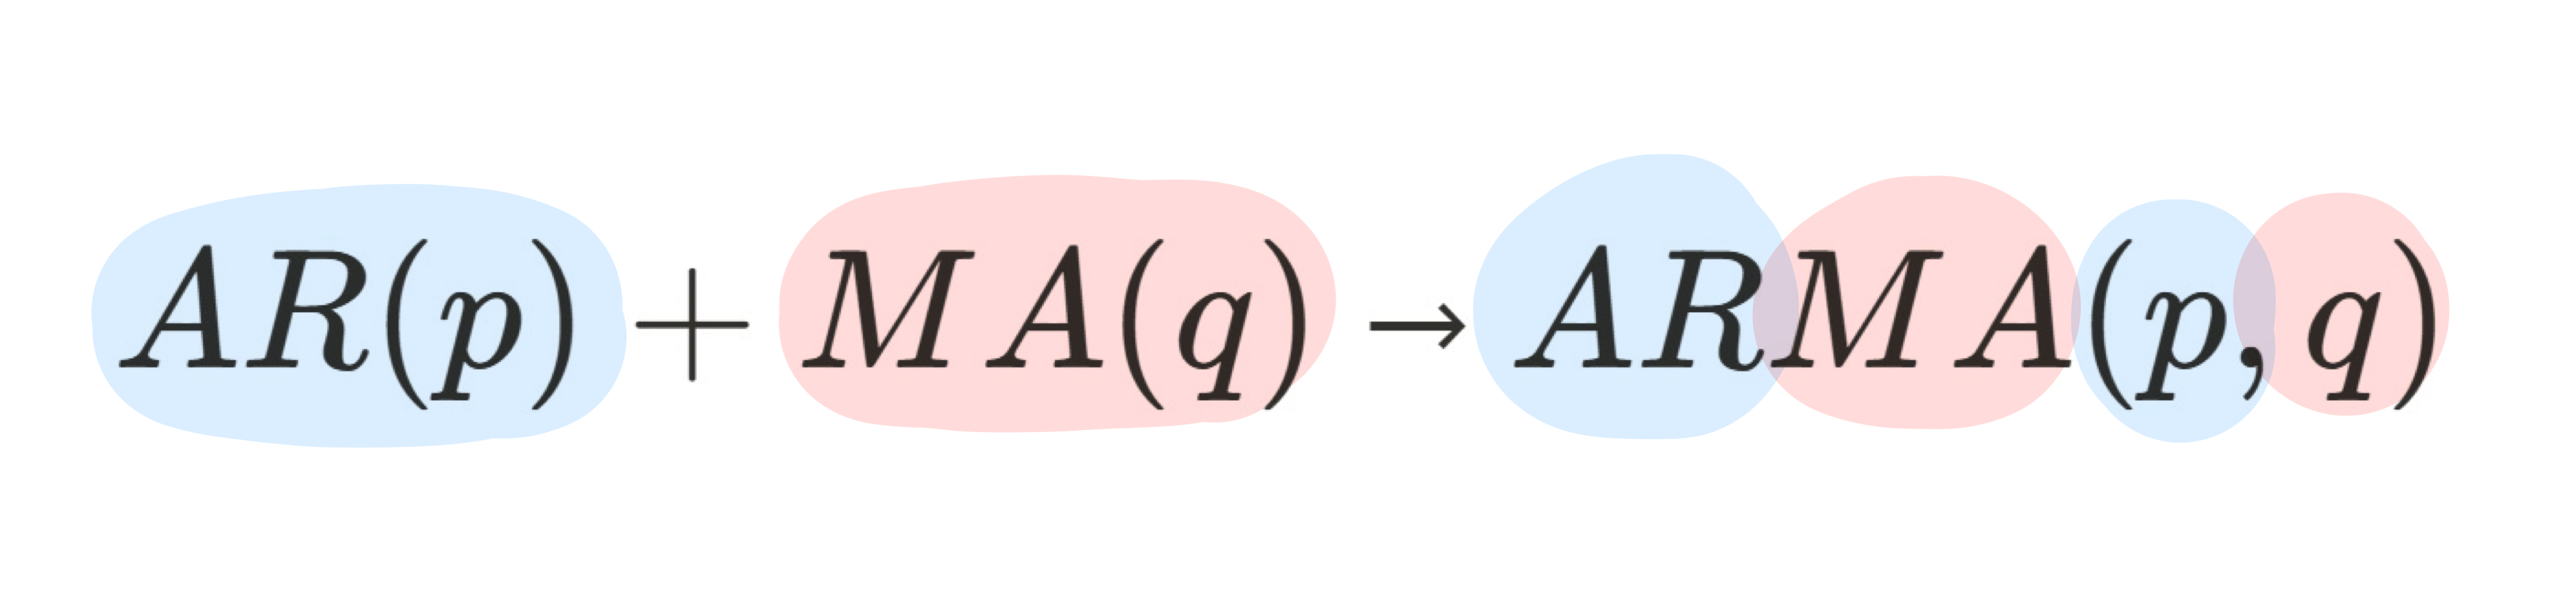

$$
y_t = c+\phi_1y_{t-1}+\dots+\phi_py_{t-p}+\varepsilon_t+\theta_1\varepsilon_{t-1}+\dots+\theta_q\varepsilon_{t-q}
$$

- 충격은 하루에 하나이고, 그 여파가 두 길로 넘어옴

**특징**
- 같은 장부를 AR만으로 설명하려면 여러 시차를 넣어야 함. ARMA는 더 적은 계수로 설명할 수 있음.
- ARMA 모형도 마찬가지로 **AR 부분이 정상성** 조건을, **MA 부분이 가역성** 조건을 각각 만족해야 함.

**ARMA 특수 경우**

| 모형 | 의미 |
| --- | --- |
| ARMA(p,0) | MA 부분이 없음. AR(p)와 같음 |
| ARMA(0,q) | AR 부분이 없음. MA(q)와 같음 |
| ARMA(0,0) | 둘 다 없음. 상수에 충격만 더한 백색잡음 |





#### **차수 결정 방법 : 자기 상관 함수**

**자기 상관 계수 (Auto Correlation Function, ACF) <- ARMA(p,q)에서 q 결정**

: 오늘 값과 k시점 전 값이 얼마나 닮았는지 상관계수로 잰 것. 시차 k를 바꿔 가며 구한 값을 막대로 그림.

$$
\rho(k)=\frac{Cov(y_t,\ y_{t-k})}{Var(y_t)}
$$

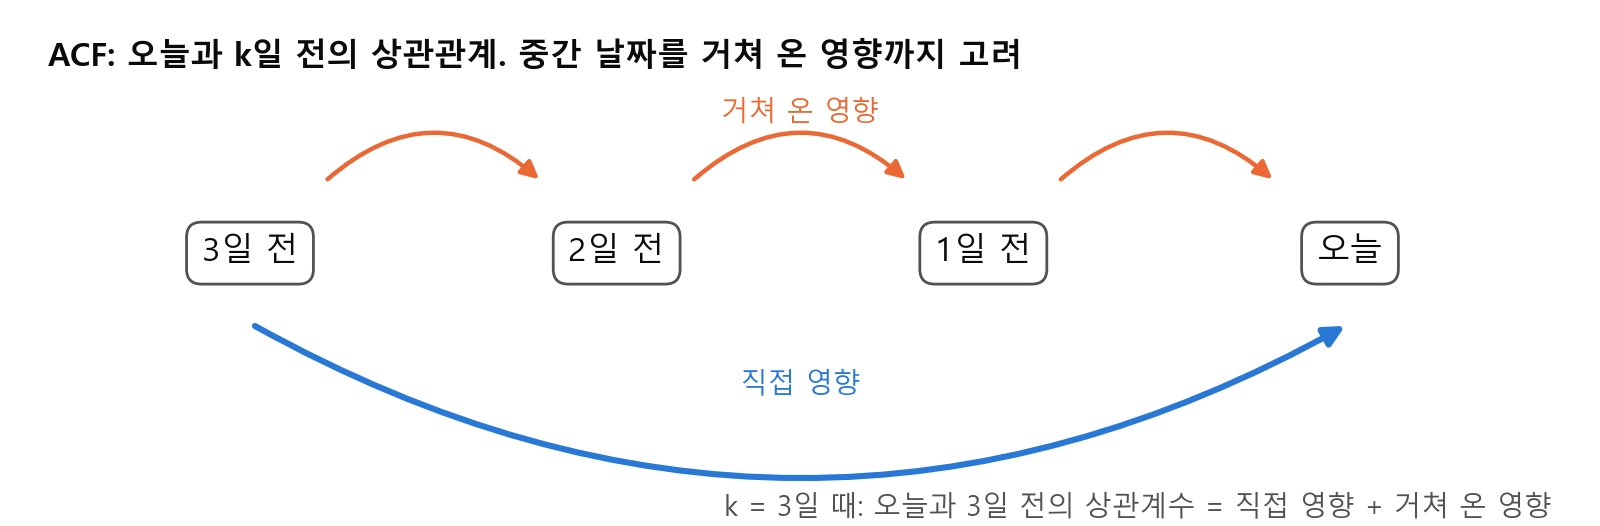

**특징**
- −1에서 1 사이의 값을 가짐. 시차 0에서는 항상 1
- 중간 날짜를 거쳐 온 영향까지 합쳐서 측정
- 그래프의 점선 안쪽이면 0으로 봅니다. 점선은 보통 $\pm 1.96/\sqrt{n}$

**부분 자기 상관 계수 (Partial Autocorrelation Function, PACF) <- ARMA(p,q)에서 p 결정**

: 중간 시점 영향을 빼고, 오늘 값과 k시점 전 값이 직접 얼마나 닮았는지를 잰 것

$$
\phi_{kk} = Corr(y_t,\ y_{t-k}\mid y_{t-1},\dots,y_{t-k+1})
$$

$$
\phi_{kk} = Corr(y_t,\ y_{t-k}\mid y_{t-1},\dots,y_{t-k+1})
$$

**특징**
- 시차 1에서는 ACF와 값이 같음.(중간 날짜가 없기 때문)

**ACF와 PACF로 차수 및 모형 결정**

| **ACF 그래프** 모습 | **PACF 그래프** 모습 | **선택 모델 및 차수** |
| --- | --- | --- |
| 천천히 감소 or 진동 감소 | p+1 시점부터 0에 근접 | **AR(p) (= ARMA(p, 0)),** p = 절단 시점 |
| q+1 시점부터 0에 근접 | 천천히 감소 or 진동 감소 | **MA(q) (= ARMA(0, q)) ,** q= 절단 시점 |
| q+1 시점부터 0에 근접 | p+1 시점부터 0에 근접 | **ARMA(p, q)** |

-> **막대가 급격히 줄어들기 직전 시차 고르기!**

### **4-2. 불안정 시계열(정상성이 없는 시계열) 분석**

| 평소가 없는 이유 | 모습 | 처방 | 다루는 곳 |
| --- | --- | --- | --- |
| 추세 | 계속 오르거나 내림. (새로 생긴 가게,아이 키) | 차분 (d) | ARIMA |
| 계절성 | 달마다 평소가 다름. (붕어빵) | 계절 차분 (D) | SARIMA |

-> **핵심 : 모형을 고치는 것이 아닌 데이터를 모형이 다룰 수 있는 숫자로 바꿔주는 것!**

**불안정 데이터 시계열 분석 프로세스**
1. 비정상 시계열 데이터 (추세 or 계절성 존재)
2. **정상성 확보** (차분 or 계절성 차분)
3. 정상 시계열
4. ARMA를 사용해 **안정적 시계열 분석**

#### **1. ARIMA (Autoregressive Integrated Moving Average)**

: **ARMA에 차분을 더한 모형**

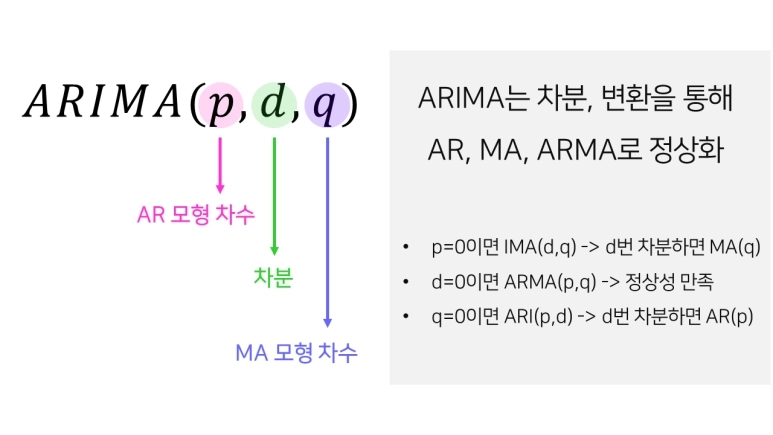

- $ARIMA(p,d,q)$
    - $p$: AR 차수
    - $d$: 차분 횟수
    - $q$: MA 차수

**흐름**

: ① 차분해서 증감을 만들기 -> ② 증감을 예측하기 -> ③ 예측한 증감을 어제 판매량에 더하기

**ARIMA 모형 특수한 경우**

| 1. 백색잡음 | ARIMA(0,0,0) |
| --- | --- |
| 2. 자기회귀 | ARIMA(p,0,0) ⇔ AR(p) |
| 3. 이동평균 | ARIMA(0,0,q) ⇔ MA(q) |
| 4. 랜덤워크 | 상수가 없는 ARIMA(0,1,0) |
| 5. 표류를 포함하는 랜덤워크 | 상수가 있는 ARIMA(0,1,0) |

**랜덤워크**

$$
Y_t = Y_{t-1} + \varepsilon_t
$$

- 상수가 없는 ARIMA(0,1,0). 앞의 2단계 식에서 제거를 통해 랜덤워크의 식 도출.
    
    
    | 2단계 식 | 뜻 | 랜덤워크에서 |
    | --- | --- | --- |
    | 상수 | 매일 보통 얼마씩 변하는가 | 상수가 없으니 뺌 |
    | 계수 × 어제 증감 | AR 부분 | AR 차수가 0이니 뺌 |
    | 오늘 충격 | 오늘 새로 생긴 변화 | 남음 |
    | 계수 × 어제 충격 | MA 부분 | MA 차수가 0이니 뺌 |

최종적으로 남는 것은 "증감(
𝑤
𝑡
w 
t
​
 ) = 오늘 충격(
𝜀
𝑡
ε 
t
​
 )". 즉, 어제 얼마나 변했든 오늘 변화와 상관이 없다는 뜻    

**표류를 포함하는 랜덤워크**

$$
Y_t = Y_{t-1} + \varepsilon_t + c
$$

- 상수가 있는 ARIMA(0,1,0). 랜덤워크에서 상수만 빼지 않고 남겨 둔 것.
- 남는 것은 "증감($w_t$) = 오늘 충격($\varepsilon_t$) + $c$". c는 **매일 보통 얼마씩 변하는가**이고, 이것을 **표류**함

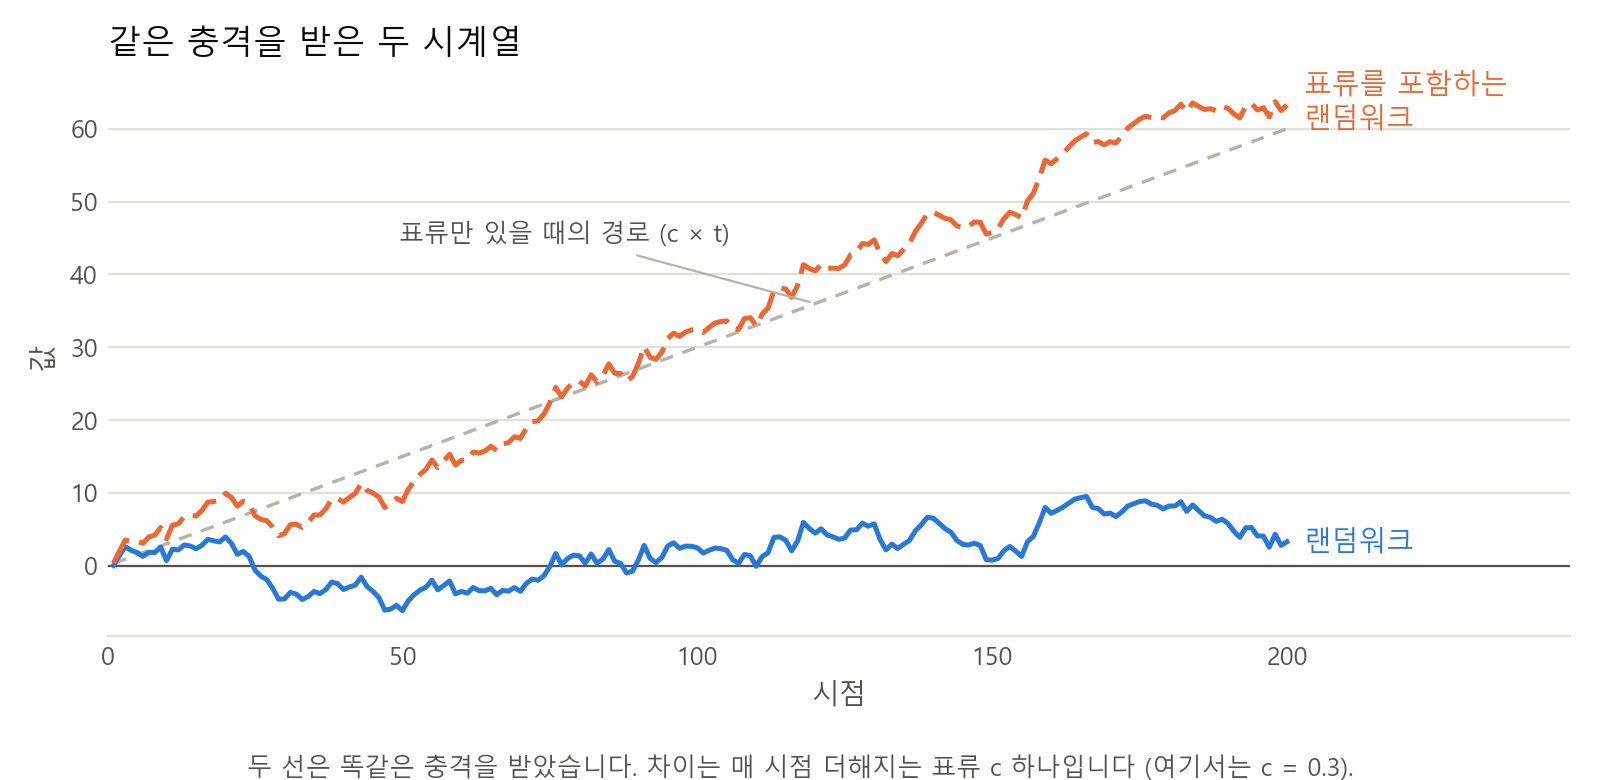

#### **2. SARIMA (Seasonal ARIMA)**

: **ARIMA에 계절 차분, 계절 AR, 계절 MA 더한 모델**

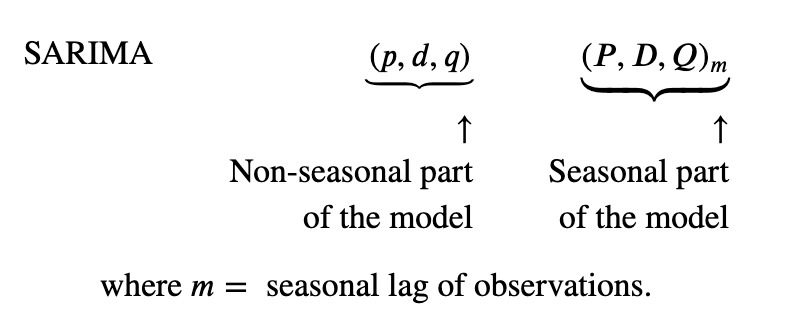

**흐름**
1. 계절 차분하기
2. 증감 예측하기
3. 판매량으로 되돌리기

**하이퍼파라미터**

$$
ARIMA(p,d,q) + \text{계절성(Seasonal) 차분} \\ \rightarrow SARIMA(p,d,q)(P, D, Q)_m
$$

| 기호 | 이름 | 의미 |
| --- | --- | --- |
| p | 비계절 AR 차수 | 바로 전 시점들의 값을 몇 개 쓰는가 |
| d | 비계절 차분 횟수 | 직전 시점 대비 차분을 몇 번 하는가 |
| q | 비계절 MA 차수 | 바로 전 시점들의 충격을 몇 개 쓰는가 |
| P | 계절 AR 차수 | 한 주기 전, 두 주기 전 값을 몇 개 쓰는가 |
| D | 계절 차분 횟수 | 한 주기 전 대비 차분을 몇 번 하는가 |
| Q | 계절 MA 차수 | 한 주기 전, 두 주기 전 충격을 몇 개 쓰는가 |
| m | 계절 주기 | 한 바퀴가 몇 시점인가. 월별 12, 분기별 4, 요일 효과 7 |

**계절성 데이터에서의 ACF/PACF**

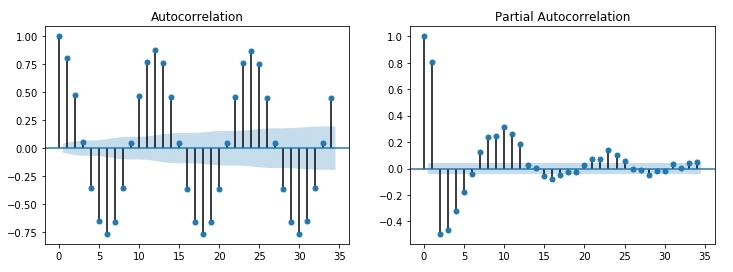

- ACF가 물결 모양으로 오르내리면서 시차 12, 24, 36에서 다시 솟음. **주기 12의 계절성이 있다는 신호**
- 물결의 높이가 줄지 않음. 평소가 없다는 뜻
- PACF도 시차 12 근처까지 띠 밖 막대가 이어져서 끊기는 자리가 없음. 이 상태로는 p와 q를 읽을 수 없음

-> **그래서 계절 차분을 먼저 수행하는 것이 중요!**

**불안정 시계열에서의 하이퍼파라미터 결정 방법**

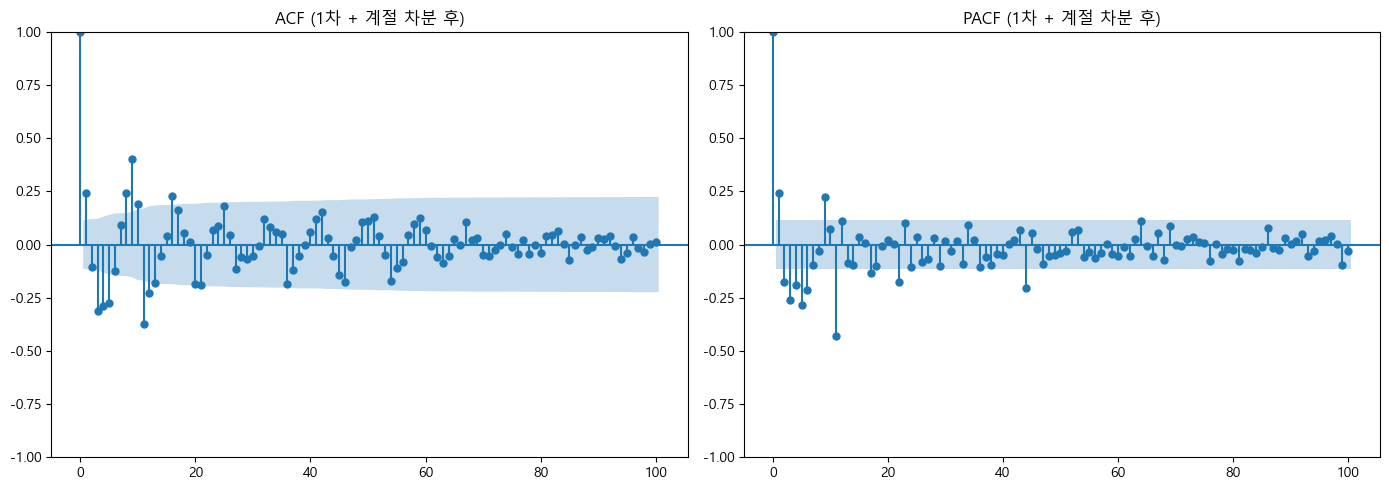

- **d, D (차분·계절 차분) 결정 방법**
    1. **ADF(단위근 검정)으로 정상성 확보 여부 판단** 후 결정
        - **정상이면?** 차분하지 않음. d = 0, D = 0입니다.
        - **정상이 아니면?** 차분한 뒤 다시 검정. 정상이 나올 때까지 반복하고, 그때의 차분 횟수가 d와 D
            - 추세 때문이면 차분을 한다(d).
            - 계절성 때문이면 계절 차분을 한다(D). 계절성은 ACF에서 주기마다 솟는 물결로 확인한다.
        - 차분 횟수는 대부분 0 또는 1이다.
        
- **p, q (AR, MA 차수) 결정 방법**
    1. 먼저 **ACF, PACF로 범위를 추정** 한 뒤
        - 앞에서 설명했던 그래프로 살펴보는 과정!
    2. AIC, BIC 같은 정보 기준으로 **그리드 서치 후, 최종 선택**
        - AIC, BIC(SC)란? : 모델 성능 평가
            
            간단하게 설명하자면 
            
            - 모델 성능을 평가하는 지표로 값이 낮을 수록 모델이 성능이 좋음을 의미
            
        - **보통 p, q를 0~3 범위 내에서** 그리드 서치 진행
        - 위 그래프를 통해 설정한 `p, q, P, Q`에서 ±1 범위 내에서 AIC, BIC를 계산!




## **5. 다변량 시계열 분석**

**단변량 vs 다변량**

|  | 예측하는 것 | 예측에 쓰는 것 | 예시 |
| --- | --- | --- | --- |
| 단변량 | 변수 1개 | 자기 자신의 과거 | 어제 판매량으로 오늘 판매량을 예측 |
| 다변량 | 변수 여러 개를 동시에 | 자기 자신의 과거와 다른 변수의 과거 | 어제 판매량과 어제 광고비로 오늘 판매량과 오늘 광고비를 각각 예측 |

### **5-1. VAR (Vector Autoregression)**

다변량 VAR(1)은 변수마다 식이 하나씩 있고, 각 식에 모든 변수의 어제 값이 들어감. 가게로 말하면 X가 판매량, Y가 광고비.

$$
X_t = a_{11} X_{t-1} + a_{12} Y_{t-1} + \varepsilon_{x,t}
$$

$$
Y_t = a_{21} X_{t-1} + a_{22} Y_{t-1} + \varepsilon_{y,t}
$$

- $a_{11}$과 $a_{22}$는 자기 자신에게서 넘어오는 영향. (AR의 계수와 같은 역할)
- $a_{12}$와 $a_{21}$이 VAR에서 새로 생긴 계수. (서로에게 주는 영향)

**추천 경우**

**VAR 모형이 적합한 경우**

- 변수들이 서로 영향을 주고받는 경우 (판매량과 광고비처럼 양방향)
- 예측뿐 아니라 "한 변수가 변하면 다른 변수가 며칠에 걸쳐 어떻게 반응하는가"를 알고 싶을 때
- 모든 변수가 정상이거나, 차분하면 정상이 되는 경우
- 변수의 수가 적고 데이터가 충분한 경우

**VAR 모형이 부적합한 경우**

- 영향이 한 방향뿐인 경우 (기온은 판매량에 영향을 주지만 판매량이 기온을 바꾸지는 않음. 이때는 단변량 모형에 기온을 설명변수로 넣으면 된다.)
- 변수는 많은데 데이터가 적은 경우. (변수가 2개이면 계수가 4개, 3개이면 9개로 빠르게 늘어나기 때문)
- 비율이 고정되지 않은 관계가 강한 경우 → 이때는 6장의 딥러닝을 고려해볼 수 있음.

#### **VAR 모델 이용한 분석 방법**

**충격 반응 함수 (IRF, Impulse-Response Function)**
- 한 변수에 충격을 한 번 주었을 때 다른 변수가 시간에 따라 어떻게 반응하는지를 보는 도구

**예측오차 분산 분해 (Variance Decomposition)**
- 예측이 빗나간 정도를 "어느 쪽 충격 탓인가"로 나누어 비율로 보여줌.

## **6. 딥러닝을 활용한 시계열 분석**

**등장 배경 : 전통 통계 모델의 한계**

1. 데이터가 많으면 처리 속도가 느려짐
2. 크기가 고정된 데이터만 가능
3. 비선형 패턴 포착이 어려움

#### **순환 신경망 (RNN 계열)**

: RNN/LSTM/GRU

**적합한 경우**
- 순차적 패턴이 중요한 시계열 데이터
- 과거 정보가 미래 예측에 영향을 주는 문제
- 시계열 길이와 목적에 따라 모델 선택 가능

**부적합한 경우**
- 매우 긴 시계열(수천~수만 step)에서는 학습이 어려울 수 있음
- 병렬 처리 효율이 낮음
- Transformer 계열 대비 학습 속도가 느린 편

| 모델 | 장점 | 단점 | 사용 예시 |
| --- | --- | --- | --- |
| **RNN** | 간단, 빠름 | 장기 의존성 학습 불가 | 짧은 시계열 (일주일 주가) |
| **LSTM** | 장기 의존성 학습 가능 | 복잡, 느림 | 분기별 재무제표 예측 |
| **GRU** | LSTM보다 빠름, 적당한 성능 | LSTM보다 장기 의존성 약함 | 실시간 센서 데이터 예측 |

#### **Transformer 계열**

**1. Informer (장기 예측 특화)**

- **특징 :** 불필요한 연산을 줄여 계산 복잡도를 대폭 낮춘 모델
- **실무 강점 :** 매우 긴 시계열 데이터 처리에 강력함

**2️. Autoformer (주기성 포착 특화)**

- **특징 :** 시계열의 전통적 기법인 '요소 분해(추세/계절성)' 개념을 딥러닝 구조에 직접 결합한 모델
- **실무 강점 :** 연간 계절성 등 주기 패턴이 뚜렷하게 나타나는 판매량 예측에 압도적인 성능을 보임

**3️. TFT (Temporal Fusion Transformer - 실무 활용도 1위!)**

- **특징 :** 과거 데이터뿐만 아니라 다양한 외부 변수(날씨, 휴일 유무 등)를 섞어서 예측할 수 있는 다목적 아키텍처
- **실무 강점 :** 어떤 변수가 예측에 가장 중요했는지 어텐션 스코어를 통한 해석이 가능해, 설명력이 중요한 유통/비즈니스 수요 예측에 가장 많이 쓰임

| 모델 | 언제 사용? | 사용 예시 | 장점 | 단점 |
| --- | --- | --- | --- | --- |
| **Informer** | 긴 시계열 | 전력 수요 예측 | 계산 효율적 | 짧은 시계열 과적합 |
| **Autoformer** | 주기성 뚜렷 | 월별 판매량 예측 | 주기 포착 우수 | 구조 복잡 |
| **TFT** | 외생 변수 많음 | 유통 수요 예측 | 해석 가능 | 학습 시간 오래 걸림 |

#### **3. Foundation Model**

: 거대한 데이터로 사전 학습하여 다양한 문제를 해결할 수 있는 범용 모델

**특징**
- 특정 문제 전용 ❌
- 범용적(Generalized) ✅
- 사전 학습 후 Fine-tuning으로 특화

**유형**

| 유형 | 설명 | 예시 |
| --- | --- | --- |
| **LLM 기반 모델** | LLM을 시계열 분석에 활용 | Prompting, Fine-tuning |
| **시계열 전용 Foundation Model** | 시계열 데이터로 사전 학습된 범용 모델 | TimeGPT, TimesFM, Moirai, Chronos |

**LLM 기반 모델 활용 방식**
- **Without Adaptation**
    - LLM이 이미 시계열 지식을 가지고 있다고 가정
    - **프롬프트 엔지니어링**에 집중
- **Adapt LLM**
    - LLM을 **시계열 데이터로 Fine-tuning**
- **Adapt to LLM**
    - 시계열을 **텍스트로 변환** 후 LLM 활용
    - 예: 숫자 시계열 → “값이 증가 추세”, “주기성 있음” 등 텍스트화

#### **4. 딥러닝 모델 선택 가이드**

**핵심 트레이드오프**

- **단순함 vs 성능**: RNN < LSTM/GRU < Transformer
- **해석 가능 vs 정확도**: 통계 모델 < 딥러닝 (단, TFT는 어텐션으로 해석 가능)
- **학습 시간 vs 예측 성능**: 간단한 모델은 빠르고, 복잡한 모델은 정확함
- **데이터 크기**: 적으면 → 통계 모델/RNN, 많으면 → Transformer가 적합

**상황별 추천 모델**

| 상황 | 추천 모델 | 이유 |
| --- | --- | --- |
| 짧은 시계열 (< 100) | 통계 모델, RNN | 데이터가 적으면 단순한 모델이 과적합 방지에 유리 |
| 중간 길이 (100~1000) | LSTM, GRU | 장기 의존성 학습 가능, 적절한 복잡도 |
| 매우 긴 시계열 (1000+) | Informer, Autoformer | 긴 시퀀스의 전역 패턴 효율적 학습 |
| 장기 의존성 중요 | LSTM, Transformer | GRU보다 먼 과거 정보 유지에 강함 |
| 주기 패턴 뚜렷 | Autoformer | 추세/계절성 분해로 주기 포착 우수 |
| 외생 변수 많음 | TFT | 정적/동적 변수 융합 + 해석 가능 |
| 대규모 데이터 | Transformer 계열 | 병렬 연산으로 학습 효율적 |
| 범용 예측 필요 | Foundation Model | 사전 학습된 지식으로 빠른 적용 |





